In [1]:
%pylab inline

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [2]:
from __future__ import print_function
from deltasigma import *
from IPython.core.display import Image

# Modulator realization and dynamic range scaling - # demo3

In this ipython notebook, the following is demonstrated:

 * A 5th order delta sigma modulator is synthesized, with optimized zeros and an OSR equal to 42.

 * We then convert the synthesized NTF into `a`, `g`, `b`, `c` coefficients for the `CRFB` modulator structure.
 
 * The maxima for each state are evaluated.
 
 * The `ABCD` matrix is scaled so that the state maxima are less than the specified limit.

 * The state maxima are re-evaluated and limit compliance is checked.

**NOTE:** This is an ipython port of `dsdemo3.m`, from the **[MATLAB Delta Sigma Toolbox](http://www.mathworks.com/matlabcentral/fileexchange/19-delta-sigma-toolbox)**, written by Richard Schreier.

## Delta sigma modulator synthesis

In [3]:
order = 5
R = 42
opt = 1
H = synthesizeNTF(order, R, opt)

Let's inspect the NTF, printing out the transfer function and plotting poles and zeros with respect to the unit circle.

In [4]:
print(pretty_lti(H))

        (z^2 - 1.995z + 1) (z^2 - 1.998z + 1) (z - 1)         
--------------------------------------------------------------
 (z^2 - 1.614z + 0.6657) (z^2 - 1.797z + 0.8552) (z - 0.7783) 


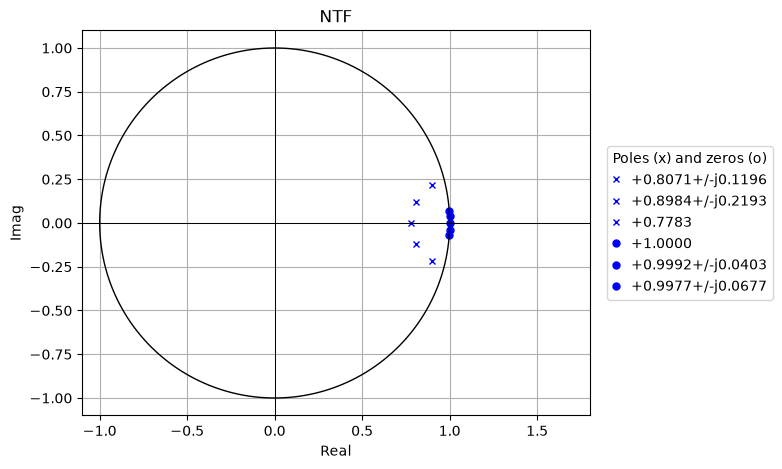

In [5]:
figure(figsize=(10, 5))
plotPZ(H, showlist=True)
title('NTF');

## Evaluation of the coefficients for a CRFB topology
The CRFB topology is depicted in the following diagram.

In [6]:
Image(url='http://python-deltasigma.readthedocs.org/en/latest/_images/CRFB.png', retina=True)

Since the modulator order is 5, we're interested in the topology for odd order modulators.

## Unscaled modulator

### Calculate the coefficients

In [7]:
a, g, b, c = realizeNTF(H)

### Feed-in selection
We'll use a single feed-in for the input, to have a maximally flat STF.

This means setting $\ b_n = 0, \ \forall n > 1$.

In [8]:
b = np.concatenate((b[0].reshape((1, )), np.zeros((b.shape[0] - 1, ))), axis=0)

In [9]:
from itertools import zip_longest
from IPython.display import display, HTML

ilabels = ['#1', '#2', '#3', '#4', '#5', '#6']
rows = [
    ['Coefficients', 'DAC feedback', 'Resonator feedback',
     'Feed-in', 'Interstage'],
    ['', 'a(n)', 'g(n)', 'b(n)', 'c(n)']
]
rows.extend(
    list(x) for x in zip_longest(
        ilabels,
        a.tolist(),
        g.tolist(),
        b.tolist(),
        c.tolist(),
        fillvalue=""
    )
)
html = "<table>"
for i, row in enumerate(rows):
    html += "<tr>"
    for cell in row:
        tag = "th" if i < 2 else "td"
        html += f"<{tag}>{cell}</{tag}>"
    html += "</tr>"
html += "</table>"

display(HTML(html))

Coefficients,DAC feedback,Resonator feedback,Feed-in,Interstage
,a(n),g(n),b(n),c(n)
#1,0.0006670795813848868,0.001622050471799641,0.0006670795813848868,1.0
#2,0.008582635287917301,0.004592653480622877,0.0,1.0
#3,0.05520145164491905,,0.0,1.0
#4,0.24760725165068193,,0.0,1.0
#5,0.5569351152496324,,0.0,1.0
#6,,,0.0,


### Calculate the state maxima

In [10]:
ABCD = stuffABCD(a, g, b, c);
u = np.linspace(0, 0.6, 30);
N = int(1e4); 
T = np.ones((1, N))
maxima = np.zeros((order, len(u)))
for i in range(len(u)):
    ui = u[i]
    v, xn, xmax, _ = simulateDSM(ui*T, ABCD);
    maxima[:, i] = np.squeeze(xmax)
    if any(xmax > 1e2):
        umax = ui;
        u = u[:i];
        maxima = maxima[:, :i]
        break;
# save the maxima
prescale_maxima = np.copy(maxima)
print('The state maxima have been evaluated through simulation.')

C:\Users\adcroche\Desktop\Nouveau dossier\python-deltasigma\deltasigma\_simulateDSM.py:186: UserWarning: Using the pure Python implementation of simulateDSM
  warn('Using the pure Python implementation of simulateDSM')


The state maxima have been evaluated through simulation.


### Plot of the state maxima

(1e-06, 10)

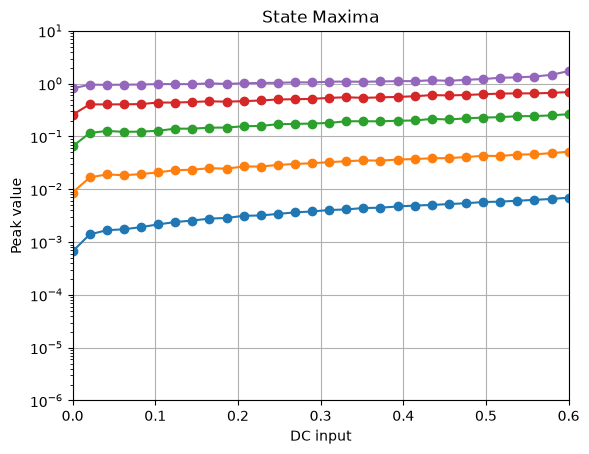

In [11]:
for i in range(order):
    semilogy(u, maxima[i, :], 'o-', label='State %d' % (i + 1))

grid(True)
title('State Maxima')
ylabel('Peak value')
xlabel('DC input')
xlim([0, 0.6])
ylim([1e-6, 10])

## Scaled modulator
### Calculate the scaled coefficients

In [12]:
ABCDs, umax, _ = scaleABCD(ABCD, N_sim=1e5)
as_, gs, bs, cs = mapABCD(ABCDs)
print('\nScaled modulator, umax = %.2f\n' % umax)


Scaled modulator, umax = 0.58



In [13]:
from itertools import zip_longest
from html import escape
from IPython.display import display, HTML

ilabels = ['#1', '#2', '#3', '#4', '#5', '#6']

rows = [
    ['Coefficients', 'DAC feedback', 'Resonator feedback', 'Feed-in', 'Interstage'],
    ['', 'a(n)', 'g(n)', 'b(n)', 'c(n)']
]

rows.extend(zip_longest(
    ilabels, as_.tolist(), gs.tolist(), bs.tolist(), cs.tolist(),
    fillvalue=""
))

html = '<table><tbody>'

for i, row in enumerate(rows):
    tag = 'th' if i < 2 else 'td'
    html += '<tr>' + ''.join(
        f'<{tag}>{escape(str(value))}</{tag}>'
        for value in row
    ) + '</tr>'

html += '</tbody></table>'

display(HTML(html))

Coefficients,DAC feedback,Resonator feedback,Feed-in,Interstage
,a(n),g(n),b(n),c(n)
#1,0.10029776281151091,0.008508036472787889,0.10029776281151091,0.13534708993995956
#2,0.1746558669940866,0.010817262175037977,0.0,0.19064921465576795
#3,0.21416477448375199,,0.0,0.38027088890604577
#4,0.3653036244415176,,0.0,0.4245670860433548
#5,0.34885226412300385,,0.0,1.5964784309189959
#6,,,0.0,


### Calculate the state maxima

In [14]:
u = np.linspace(0, umax, 30)
N = int(1e4)
T = np.ones((N,))
maxima = np.zeros((order, len(u)))
for i in range(len(u)):
    ui = u[i]
    v, xn, xmax, _ = simulateDSM(ui*T, ABCDs)
    maxima[:, i] = xmax.squeeze()
    if any(xmax > 1e2):
        umax = ui;
        u = u[:i]
        maxima = maxima[:, :i]
        break
print('The state maxima have been re-evaluated through simulation.')
print("The maximum input was found to be %.6f" % umax)

The state maxima have been re-evaluated through simulation.
The maximum input was found to be 0.583333


### Plot of the state maxima after scaling

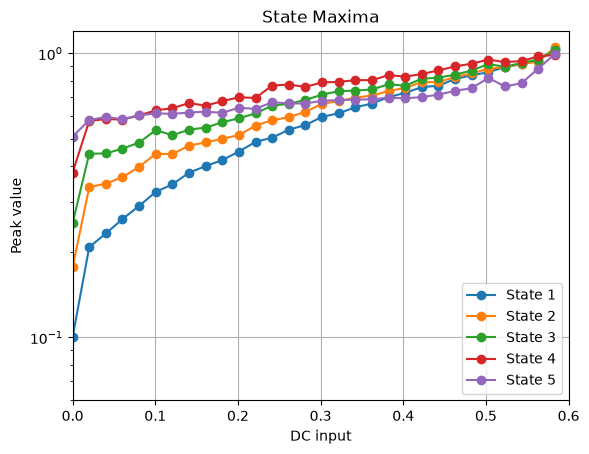

In [15]:
for i in range(order):
    semilogy(u, maxima[i, :], 'o-', label='State %d' % (i + 1))

grid(True)
title('State Maxima')
ylabel('Peak value')
xlabel('DC input')
xlim([0, 0.6])
ylim([6e-2, 1.2])
legend(loc=4)

### System version information

In [16]:
import sys
import numpy
import scipy
import matplotlib
import deltasigma

print("Python      :", sys.version)
print("NumPy       :", numpy.__version__)
print("SciPy       :", scipy.__version__)
print("Matplotlib  :", matplotlib.__version__)
print("DeltaSigma  :", deltasigma.__file__)

Python      : 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
NumPy       : 2.5.4
SciPy       : 1.18.1
Matplotlib  : 3.11.2
DeltaSigma  : C:\Users\adcroche\Desktop\Nouveau dossier\python-deltasigma\deltasigma\__init__.py
